# 08 · Reinforcement learning

Notebook 07 solved the buy-or-wait problem with a **price model** (a jump
process), and the solution was only as good as that model. Here I skip the
price model entirely. Fitted Q-iteration learns the value of waiting
**directly from what actually happened** on past trips.

**Key takeaways**
1. Learning the value of waiting straight from historical price paths works
   better than every approach so far: **about 10% saved per trip from 60
   days out, 7.6% from 45 and 6.2% from 30**, losing money on only 5–8% of
   trips.
2. It beats **LightGBM** because it optimizes the real goal (the final
   price paid) over the whole remaining window, rather than a stand-in
   ("will it drop 5% soon?").
3. It beats **dynamic programming** because it doesn't assume a price model.
   It sees the same rich information as LightGBM and learns from real
   outcomes, including trips that stay cheap or expensive.
4. Savings are positive in every test month from 30–60 days out, but they
   **vary a lot by season**: 12–14% for decisions made in June, 2–7% from
   July to September. Confidence intervals and a fair head-to-head comparison
   are in notebook 09.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from flight_pricing.backtest import (START_DAYS, buy_day, decision_date, eligible,
                                     load_fare_matrix, price_paid)
from flight_pricing.data import connect
from flight_pricing.features import build_features
from flight_pricing.plotting import SERIES, TEXT_MUTED, use_style
from flight_pricing.rl import walk_forward_q

use_style()
con = connect()
df = build_features(con)
trips, F = load_fare_matrix(con, full_window_only=False)
TEST_MONTHS = pd.period_range("2022-06", "2022-09", freq="M")

## The idea

On any day, the choice is to buy now at today's fare, or wait and act
optimally later. Let $W_t(s)$ be the **expected cost of waiting** when I'm
$t$ days out and know $s$ (today's fare vs. the route's usual level, recent
moves, days to departure, the route: the same inputs as notebook 06).

If I wait, the next price I see is on day $u < t$. Then I either buy at
that price or keep waiting, whichever is cheaper:

$$W_t(s) = \mathbb{E}\Big[\min\big\{\text{cost}(x_u),\ W_u(s_u)\big\} \;\Big|\; s\Big]$$

This is the Bellman equation again. The difference from notebook 07 is how
the expectation is computed:

- **Dynamic programming:** assume a price model, and calculate the
  expectation from it.
- **Fitted Q-iteration:** take every past trip that was at day $t$ in state
  $s$, compute the realized $\min\{\text{cost}(x_u), W_u(s_u)\}$, and fit a
  regression (LightGBM) to predict it from $s$. The regression *is* the
  expectation.

Because $u$ is always closer to departure than $t$, I can fit $W_2$ first,
then $W_3$ using $W_2$, and so on up to $W_{60}$: 59 small regressions,
each built on the ones before. The rule is then: **buy on day $t$ if
$\text{cost}(x_t) \le W_t(s_t)$.**

**Same honest setup as before.** For each test month, all 59 regressions
use only trips that departed before the month began, and the route's usual
fare comes from those trips too.

## Two versions of "cost"

- **price:** cost $= e^{x}$, the fare relative to the route's usual fare.
  This minimizes expected dollars, and it's the version I use as the main
  result (the same default as notebook 07, chosen before seeing these
  results).
- **log:** cost $= x$, the log fare. Log differences are roughly
  percentages, so this targets average % saved.

In [2]:
B = {obj: walk_forward_q(df, trips, F, TEST_MONTHS, objective=obj) for obj in ("price", "log")}

def score_policy(Bm):
    rows = []
    for s in START_DAYS:
        month = decision_date(trips, s).dt.to_period("M").to_numpy()
        idx = np.flatnonzero(eligible(trips, F, s) & np.isin(month, TEST_MONTHS))
        day = buy_day(F[idx], Bm[idx], s)
        p0 = F[idx, s]
        pct = (p0 - price_paid(F[idx], day)) / p0
        rows.append({"start": f"{s}d", "trips": len(idx), "avg_saved_pct": np.nanmean(pct),
                     "total_saved_pct": np.nansum(pct * p0) / p0.sum(), "avg_saved_usd": np.nanmean(pct * p0),
                     "share_lost_money": np.mean(pct < 0), "share_waited": np.mean(day < s),
                     "month": month[idx], "pct": pct})
    return pd.DataFrame(rows)

res = {obj: score_policy(Bm) for obj, Bm in B.items()}
cols = ["start", "trips", "avg_saved_pct", "total_saved_pct", "avg_saved_usd", "share_lost_money", "share_waited"]
res["price"][cols].round(3)

,start,trips,avg_saved_pct,total_saved_pct,avg_saved_usd,share_lost_money,share_waited
0,60d,10361,0.098,0.131,18.232,0.050,0.575
1,45d,17311,0.076,0.115,15.772,0.063,0.549
2,30d,21315,0.062,0.102,14.308,0.085,0.623
3,21d,24558,0.034,0.067,9.473,0.103,0.447
4,14d,26044,0.005,0.022,3.257,0.104,0.309


In [3]:
res["log"][cols].round(3)

,start,trips,avg_saved_pct,total_saved_pct,avg_saved_usd,share_lost_money,share_waited
0,60d,10361,0.104,0.140,19.425,0.059,0.615
1,45d,17311,0.075,0.118,16.281,0.078,0.605
2,30d,21315,0.058,0.102,14.304,0.107,0.680
3,21d,24558,0.026,0.063,8.931,0.134,0.507
4,14d,26044,-0.002,0.018,2.616,0.136,0.368


**Main result (price):** from 60 days out the policy saves **9.8% per trip**
(13% of total spend), from 45 days **7.6%**, from 30 days **6.2%** ($14 per
trip), and it loses money on only 5–10% of trips. From 14 days out there's
very little left to win, consistent with every other approach.

**The log version** saves slightly more from 60 days out (10.4%) and
slightly less closer in, and loses money a bit more often. The conclusions
don't depend on which version I pick.

The policy waits on about half to two-thirds of trips starting 30–60 days
out. So it isn't just "always wait" or "always buy": it picks which trips to
wait on.

## How it compares

For reference, here are the average % saved per trip by the earlier
approaches on the same test trips, from notebooks 05–07. Notebook 09 redoes
this comparison properly, with confidence intervals and paired tests.

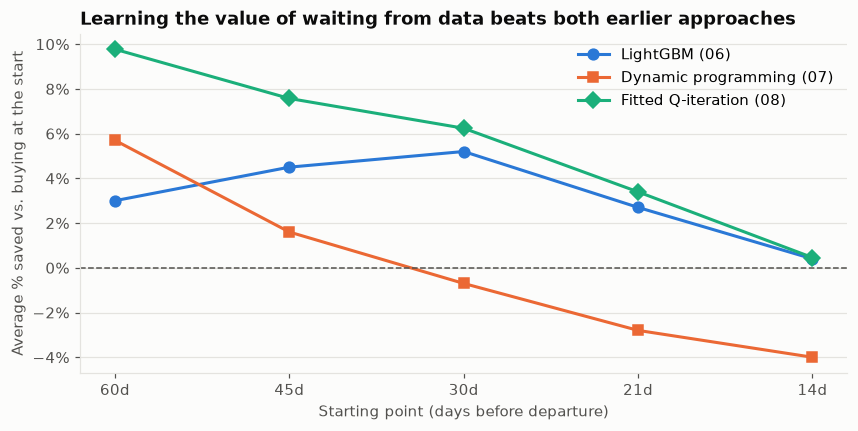

,start,LightGBM (06),Dynamic programming (07),Fitted Q-iteration (08)
0,60d,0.030,0.057,0.098
1,45d,0.045,0.016,0.076
2,30d,0.052,-0.007,0.062
3,21d,0.027,-0.028,0.034
4,14d,0.004,-0.040,0.005


In [4]:
earlier = pd.DataFrame({
    "start": [f"{s}d" for s in START_DAYS],
    "LightGBM (06)": [0.030, 0.045, 0.052, 0.027, 0.004],
    "Dynamic programming (07)": [0.057, 0.016, -0.007, -0.028, -0.040],
})
compare = earlier.assign(**{"Fitted Q-iteration (08)": res["price"].avg_saved_pct.to_numpy()})

fig, ax = plt.subplots()
for col, color, marker in zip(compare.columns[1:], SERIES, ["o", "s", "D"]):
    ax.plot(compare.start, compare[col], color=color, marker=marker, markersize=7, label=col)
ax.axhline(0, color=TEXT_MUTED, linewidth=1, linestyle="--")
ax.set_title("Learning the value of waiting from data beats both earlier approaches")
ax.set_xlabel("Starting point (days before departure)")
ax.set_ylabel("Average % saved vs. buying at the start")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.legend(loc="upper right")
plt.show()
compare.round(3)

**Why it beats LightGBM (06).** The classifier answered a stand-in
question, "will the fare drop 5% within the next few weeks?", and a tuned
cutoff turned that into a decision. Fitted Q-iteration optimizes the actual
goal, the final price paid, over the **whole** remaining window. That
matters most from far out, where the gain comes from a slow decline: 9.8% vs.
3.0% from 60 days out.

**Why it beats dynamic programming (07).** DP's price model only knew a
fare relative to the route's usual level, so it mistook trips that stay
cheap or expensive for temporary swings. Fitted Q-iteration uses the same
rich inputs as LightGBM and learns from what actually happened next, so
that mistake never gets built in.

It even beats "buy 21 days out" from 60 days out (9.8% vs. 9.6%), the simple
rule that beat LightGBM there, and that rule's 21 days was suggested by
exploring this same data.

## Is it consistent across months?

In [5]:
r = res["price"]
by_month = pd.DataFrame({
    row.start: pd.Series(row.pct).groupby(pd.Series(row.month).astype(str)).mean()
    for row in r.itertuples()}).T
by_month.round(3)

,2022-06,2022-07,2022-08,2022-09
60d,0.140,0.069,NaN,NaN
45d,0.126,0.061,0.036,NaN
30d,0.118,0.065,0.018,0.026
21d,0.077,0.037,-0.005,0.023
14d,0.025,0.003,-0.009,-0.003


Savings are positive in every test month for the 30–60-day starting points,
so the gains aren't coming from one lucky month. But their **size varies a
lot**:

- **June decisions** (summer travel): 12–14% saved.
- **July:** about 6–7%.
- **August–September:** 2–4%.

*My guess:* early-summer fares started high and fell as airlines adjusted
capacity, which gave waiting more room to pay off. It also means the overall
averages above lean on June. An honest summary is "about 2–14% depending on
the season", and the model should be tested on other years before trusting
any single number.

## When does it choose to wait?

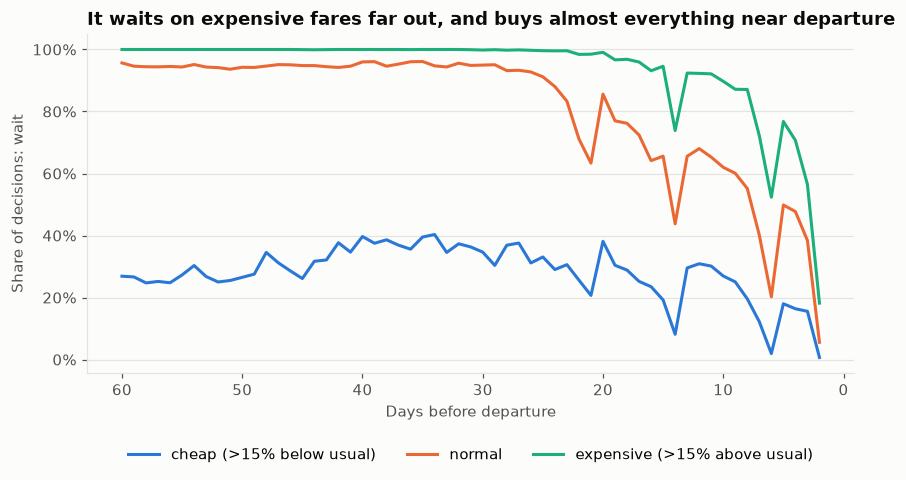

In [6]:
test_rows = (df.searchDate >= TEST_MONTHS[0].start_time) & (df.searchDate <= TEST_MONTHS[-1].end_time)
d = df.loc[test_rows, ["origin", "dest", "flightDate", "days_ahead", "log_vs_route"]].copy()
from flight_pricing.model import make_trip_index
idx = make_trip_index(trips).reindex(pd.MultiIndex.from_frame(
    d[["origin", "dest", "flightDate"]].astype({"origin": str, "dest": str}))).to_numpy().astype(int)
d["wait"] = ~B["price"][idx, d.days_ahead.to_numpy()]
d["fare_level"] = pd.cut(d.log_vs_route, [-np.inf, -0.15, 0.15, np.inf],
                         labels=["cheap (>15% below usual)", "normal", "expensive (>15% above usual)"])
wait_share = d.groupby(["days_ahead", "fare_level"], observed=True).wait.mean().unstack()

fig, ax = plt.subplots()
for col, color in zip(wait_share.columns, SERIES):
    ax.plot(wait_share.index, wait_share[col], color=color, label=col)
ax.set_title("It waits on expensive fares far out, and buys almost everything near departure")
ax.set_xlabel("Days before departure")
ax.set_ylabel("Share of decisions: wait")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.invert_xaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
plt.show()

The learned policy matches the earlier findings, without being told any of
them:

- **Far out, at normal or high fares, it almost always waits** (95–100%),
  which rides the slow decline from 60 to 30 days out (notebook 03's
  booking curve).
- **At cheap fares, it waits only 25–40% of the time.** There's little room
  to fall.
- **The wait share dips sharply right at 21, 14 and 7 days.** The policy
  learned to buy just before each deadline passes, which is exactly the
  behavior notebook 03's deadline jumps call for.
- **In the last few days it buys almost everything**, ahead of the late
  climb.

## Caveats

- **One season of data.** All of this is learned from and tested on
  Apr–Oct 2022. The market has changed since (Spirit Airlines ceased
  operations in 2026), so the policy would need retraining on current fares.
- **Listed fares**, not total cost with bag fees.
- **Uncertainty:** these are point estimates. Notebook 09 adds route-clustered
  confidence intervals and paired comparisons against the other strategies.